# SafeStair — Dynamic Programming · Versão com sensores (simulação)
**Challenge Motiva + FIAP 2026/2027 · Engenharia de Software · Turma 2ESPR · Squad 6**

| Integrante | RM |
|---|---|
| Marcelo Checchia Pivello de Toledo | 538697 |
| Nícolas Miguel Bittencourt Tanajura | 568108 |
| Rafael Benez Martins | 574994 |

> **Este notebook é complementar ao `notebook.ipynb`.** O notebook principal usa o dataset real da Motiva (histórico de falhas do SAP). Este aplica **os mesmos algoritmos** ao tipo de dado que o SafeStair propõe coletar: leituras de sensores de vibração, temperatura, corrente/tensão, trepidação, nível de óleo e velocidade. Como a Linha 4 ainda não tem esses sensores, as leituras são **simuladas** (`scripts/gerar_sensores.py`, semente fixa) para as **197 escadas reais**, e os perfis de falha são sorteados, **sem relação com o histórico do SAP**.

O objetivo é mostrar que a camada algorítmica está pronta para receber a telemetria e que os limites usados são os mesmos do `ManutencaoService` (DDD-Java) e do Database Design.

1. **Degradação acumulada** por escada ao longo das leituras diárias, em três versões, com medição e **ranking por criticidade**.
2. **Rede de estações como grafo**, com **BFS** e **Dijkstra** a partir da base.
3. **A\*** com heurística justificada × Dijkstra.
4. **`planejar_turno(base, horas)`** sobre o ranking dos sensores.

In [1]:
import sys, json, math, time, heapq, random
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

sys.setrecursionlimit(20_000)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

DADOS = Path("data")
FIGURAS = Path("figuras") / "sensores"; FIGURAS.mkdir(parents=True, exist_ok=True)

leituras = pd.read_csv(DADOS / "sensores" / "leituras_sensores.csv", parse_dates=["dt_leitura"])
escadas = pd.read_csv(DADOS / "escadas.csv")
rede = json.loads((DADOS / "rede_estacoes.json").read_text(encoding="utf-8"))
nomes_est = {v["id"]: v["nome"] for v in rede["vertices"]}

leituras = leituras.sort_values(["cd_escada", "dt_leitura"]).reset_index(drop=True)
print(f"Leituras simuladas: {len(leituras)} linhas · {leituras.cd_escada.nunique()} escadas · "
      f"{leituras.dt_leitura.min():%d/%m/%Y} a {leituras.dt_leitura.max():%d/%m/%Y}")
print(f"Rede: {len(rede['vertices'])} vértices · {len(rede['arestas'])} arestas · base = {rede['base']}")
leituras.head()

Leituras simuladas: 4728 linhas · 197 escadas · 01/09/2026 a 24/09/2026
Rede: 20 vértices · 22 arestas · base = BASE


,cd_escada,dt_leitura,vibracao_mm_s,temperatura_c,corrente_a,tensao_v,trepidacao_hz,nivel_oleo_pct,velocidade_m_s
0,BUT-ER01,2026-09-01,1.39,36.88,28.74,381.07,2.59,88.12,0.649
1,BUT-ER01,2026-09-02,1.38,38.91,28.82,376.91,2.45,89.46,0.645
2,BUT-ER01,2026-09-03,1.26,38.82,28.22,385.96,2.61,88.95,0.648
3,BUT-ER01,2026-09-04,1.46,38.61,29.83,382.35,2.72,88.75,0.652
4,BUT-ER01,2026-09-05,1.40,38.54,28.10,380.39,2.67,89.05,0.649


---
## Parte 1 — Degradação acumulada (recursão, memoização e tabulação)

### 1.1 Penalidade de cada leitura

Cada leitura diária recebe uma **penalidade** $p_i$, em pontos, que soma o quanto cada variável se afastou da faixa normal. Os limites de vibração, temperatura, nível de óleo e trepidação são **os mesmos do `ManutencaoService`**. Corrente, tensão e velocidade, que o Java ainda não usa, entram com limites relativos ao valor nominal.

Para cada variável, a severidade é $s = \min\left(2,\ \max\left(0,\ \frac{\text{desvio} - \text{normal}}{\text{crítico} - \text{normal}}\right)\right)$: vale 0 na faixa normal, 1 no limite crítico e satura em 2. A penalidade da variável é $s \times \text{peso}$, em que o peso é a penalidade crítica do Java. A escala é contínua, e não em degraus como no Java, o que separa melhor duas escadas que estão ambas "em atenção".

In [2]:
TENSAO_NOMINAL, VELOCIDADE_NOMINAL, CORRENTE_NOMINAL = 380.0, 0.65, 30.0

# variável: (tipo, limite normal, limite crítico, peso em pontos)
LIMITES = {
    "vibracao_mm_s":  ("acima",       2.0,  4.5, 25),  # mm/s
    "temperatura_c":  ("acima",      45.0, 65.0, 30),  # °C
    "trepidacao_hz":  ("acima",       3.5,  6.0, 20),  # Hz
    "nivel_oleo_pct": ("abaixo",     80.0, 40.0, 25),  # %
    "corrente_a":     ("acima_rel",  1.10, 1.30, 15),  # corrente / corrente nominal
    "tensao_v":       ("desvio_rel", 0.05, 0.10, 10),  # |V - 380| / 380
    "velocidade_m_s": ("desvio_rel", 0.02, 0.08, 15),  # |v - 0,65| / 0,65
}
NOMINAL = {"corrente_a": CORRENTE_NOMINAL, "tensao_v": TENSAO_NOMINAL, "velocidade_m_s": VELOCIDADE_NOMINAL}


def severidade(valor, tipo, normal, critico, nominal=None):
    """Severidade de uma variável: 0 na faixa normal, 1 no limite crítico, no máximo 2.

    Args:
        valor (float): valor medido.
        tipo (str): 'acima', 'abaixo', 'acima_rel' ou 'desvio_rel'.
        normal (float): limite da faixa normal.
        critico (float): limite crítico.
        nominal (float, opcional): referência para os tipos relativos.

    Returns:
        float: severidade entre 0 e 2.
    """
    if tipo == "acima":
        excesso = (valor - normal) / (critico - normal)
    elif tipo == "abaixo":
        excesso = (normal - valor) / (normal - critico)
    elif tipo == "acima_rel":
        excesso = (valor / nominal - normal) / (critico - normal)
    else:  # desvio_rel
        excesso = (abs(valor - nominal) / nominal - normal) / (critico - normal)
    return min(2.0, max(0.0, excesso))


def penalidades_por_variavel(linha):
    """Penalidade (pontos) de cada variável de uma leitura."""
    return {var: peso * severidade(linha[var], tipo, normal, crit, NOMINAL.get(var))
            for var, (tipo, normal, crit, peso) in LIMITES.items()}


def health_score_java(r):
    """Replica o ManutencaoService (DDD-Java): parte de 100 e desconta penalidades em degraus.

    Returns:
        tuple[float, str]: (health score, situação).
    """
    desc, critico = 0, False
    regras = [("vibracao_mm_s", 2.0, 4.5, 12, 25, ">"), ("temperatura_c", 45, 65, 12, 30, ">"),
              ("nivel_oleo_pct", 80, 40, 10, 25, "<"), ("trepidacao_hz", 3.5, 6.0, 10, 20, ">")]
    for var, lim_at, lim_cr, p_at, p_cr, op in regras:
        v = r[var]
        cr = v > lim_cr if op == ">" else v < lim_cr
        at = v > lim_at if op == ">" else v < lim_at
        if cr: desc += p_cr; critico = True
        elif at: desc += p_at
    hs = max(0, 100 - desc)
    if hs < 70 or critico: sit = "INTERVENCAO RECOMENDADA"
    elif hs < 85: sit = "ATENCAO"
    else: sit = "OPERANDO NORMALMENTE"
    return hs, sit


pen = leituras.apply(penalidades_por_variavel, axis=1, result_type="expand")
leituras["penalidade"] = pen.sum(axis=1).round(3)
leituras["variavel_dominante"] = pen.idxmax(axis=1).where(pen.max(axis=1) > 0, "—")
leituras[["hs_java", "situacao_java"]] = leituras.apply(health_score_java, axis=1, result_type="expand")
print("Penalidade por leitura:", leituras.penalidade.describe(percentiles=[.5, .9, .99]).round(1).to_dict())
leituras[["cd_escada", "dt_leitura", "penalidade", "variavel_dominante", "hs_java", "situacao_java"]].tail(5)

Penalidade por leitura: {'count': 4728.0, 'mean': 2.4, 'std': 7.1, 'min': 0.0, '50%': 0.0, '90%': 7.6, '99%': 37.7, 'max': 57.8}


,cd_escada,dt_leitura,penalidade,variavel_dominante,hs_java,situacao_java
4723,VSO-ER20,2026-09-20,13.770,temperatura_c,88,OPERANDO NORMALMENTE
4724,VSO-ER20,2026-09-21,18.720,temperatura_c,88,OPERANDO NORMALMENTE
4725,VSO-ER20,2026-09-22,18.555,temperatura_c,88,OPERANDO NORMALMENTE
4726,VSO-ER20,2026-09-23,24.840,temperatura_c,88,OPERANDO NORMALMENTE
4727,VSO-ER20,2026-09-24,24.105,temperatura_c,88,OPERANDO NORMALMENTE


### 1.2 Recorrência da degradação acumulada

A mesma recorrência do notebook principal, agora sobre as leituras diárias:

$$
D(0) = p_0, \qquad D(1) = p_1 + \alpha\,D(0)
$$
$$
D(i) = p_i + \alpha\,D(i-1) + \beta\,\max\bigl(0,\ D(i-1) - D(i-2)\bigr), \quad i \ge 2
$$

- $\alpha = 0{,}85$ é a **memória**: o desgaste dos dias anteriores continua pesando, mas perde 15% por leitura.
- $\beta = 0{,}5$ é o **termo de aceleração**: metade da piora recente é somada, então uma escada piorando rápido passa à frente de outra com o mesmo nível estável.

Como $D(i)$ depende de $D(i-1)$ **e** de $D(i-2)$, a recursão pura recalcula subproblemas como na sequência de Fibonacci.

In [3]:
ALFA, BETA = 0.85, 0.5


def degradacao_recursiva(p, i, contador=None):
    """Versão 1 — recursiva pura. Complexidade O(φ^n) chamadas (φ ≈ 1,618).

    Args:
        p (list[float]): penalidades das leituras, em ordem cronológica.
        i (int): índice da leitura cuja degradação acumulada se quer.
        contador (list[int], opcional): contador de chamadas, para medição.

    Returns:
        float: D(i).
    """
    if contador is not None:
        contador[0] += 1
    if i == 0:
        return p[0]
    if i == 1:
        return p[1] + ALFA * degradacao_recursiva(p, 0, contador)
    d1 = degradacao_recursiva(p, i - 1, contador)
    d2 = degradacao_recursiva(p, i - 2, contador)
    return p[i] + ALFA * d1 + BETA * max(0.0, d1 - d2)


def degradacao_memo(p, i, memo=None, contador=None):
    """Versão 2 — recursiva com memoização em dicionário. O(n) tempo e memória.

    Args:
        p (list[float]): penalidades das leituras.
        i (int): índice da leitura.
        memo (dict[int, float], opcional): cache {índice: D(índice)}.
        contador (list[int], opcional): contador de chamadas.

    Returns:
        float: D(i).
    """
    if memo is None:
        memo = {}
    if contador is not None:
        contador[0] += 1
    if i in memo:
        return memo[i]
    if i == 0:
        valor = p[0]
    elif i == 1:
        valor = p[1] + ALFA * degradacao_memo(p, 0, memo, contador)
    else:
        d1 = degradacao_memo(p, i - 1, memo, contador)
        d2 = degradacao_memo(p, i - 2, memo, contador)
        valor = p[i] + ALFA * d1 + BETA * max(0.0, d1 - d2)
    memo[i] = valor
    return valor


def degradacao_tabulacao(p):
    """Versão 3 — iterativa com tabulação (bottom-up). O(n) tempo, sem pilha de recursão.

    Args:
        p (list[float]): penalidades das leituras.

    Returns:
        list[float]: a série completa D(0), D(1), ..., D(n-1).
    """
    n = len(p)
    tabela = [0.0] * n
    tabela[0] = p[0]
    if n > 1:
        tabela[1] = p[1] + ALFA * tabela[0]
    for i in range(2, n):
        tabela[i] = p[i] + ALFA * tabela[i - 1] + BETA * max(0.0, tabela[i - 1] - tabela[i - 2])
    return tabela

### 1.3 As três versões dão o mesmo resultado?

Cada escada tem 24 leituras diárias (01 a 24/09/2026), tamanho em que a recursão pura ainda roda, então as três versões são comparadas na série completa das 197 escadas.

In [4]:
series_p = {cd: g.penalidade.tolist() for cd, g in leituras.groupby("cd_escada")}

linhas = []
for cd, p in series_p.items():
    n = len(p)
    c_rec, c_memo = [0], [0]
    t0 = time.perf_counter(); d_rec = degradacao_recursiva(p, n - 1, c_rec); t_rec = time.perf_counter() - t0
    t0 = time.perf_counter(); d_memo = degradacao_memo(p, n - 1, {}, c_memo); t_memo = time.perf_counter() - t0
    t0 = time.perf_counter(); d_tab = degradacao_tabulacao(p)[-1]; t_tab = time.perf_counter() - t0
    linhas.append({"cd_escada": cd, "D_rec": d_rec, "D_memo": d_memo, "D_tab": d_tab,
                   "chamadas_rec": c_rec[0], "chamadas_memo": c_memo[0],
                   "ms_rec": 1e3 * t_rec, "ms_memo": 1e3 * t_memo, "ms_tab": 1e3 * t_tab})
comparacao = pd.DataFrame(linhas)

iguais = np.allclose(comparacao.D_rec, comparacao.D_memo) and np.allclose(comparacao.D_memo, comparacao.D_tab)
print(f"As três versões coincidem nas {len(comparacao)} escadas:", iguais)
print(f"Diferença máxima recursiva × tabulação: {np.max(np.abs(comparacao.D_rec - comparacao.D_tab)):.2e}\n")
print(comparacao[["chamadas_rec", "chamadas_memo", "ms_rec", "ms_memo", "ms_tab"]].sum().round(1).to_string())

As três versões coincidem nas 197 escadas: True
Diferença máxima recursiva × tabulação: 0.00e+00

chamadas_rec     23914224.0
chamadas_memo        9062.0
ms_rec               4003.6
ms_memo                 3.1
ms_tab                  1.6


### 1.4 Medição: como o custo cresce com o número de leituras

Séries de tamanho $n$ crescente, sorteadas das penalidades simuladas. Cada tempo é a mediana de várias execuções. Se os sensores enviarem uma leitura por hora, um único mês já tem 720 leituras por escada; por isso medimos memoizada e tabulação até 5 000.

,n,chamadas_rec,chamadas_memo,ms_rec,ms_memo,ms_tab
0,5,12.0,8,0.0040,0.0027,0.0021
1,10,143.0,18,0.0318,0.0062,0.0045
2,15,1596.0,28,0.5726,0.0077,0.0054
3,20,17710.0,38,4.1131,0.0101,0.0079
4,22,46367.0,42,10.4531,0.0114,0.0080
5,24,121392.0,46,27.0537,0.0129,0.0093
6,26,317810.0,50,70.2424,0.0141,0.0098
7,28,832039.0,54,190.7413,0.0143,0.0106
8,100,NaN,198,NaN,0.0689,0.0700
9,720,NaN,1438,NaN,0.5224,0.3458


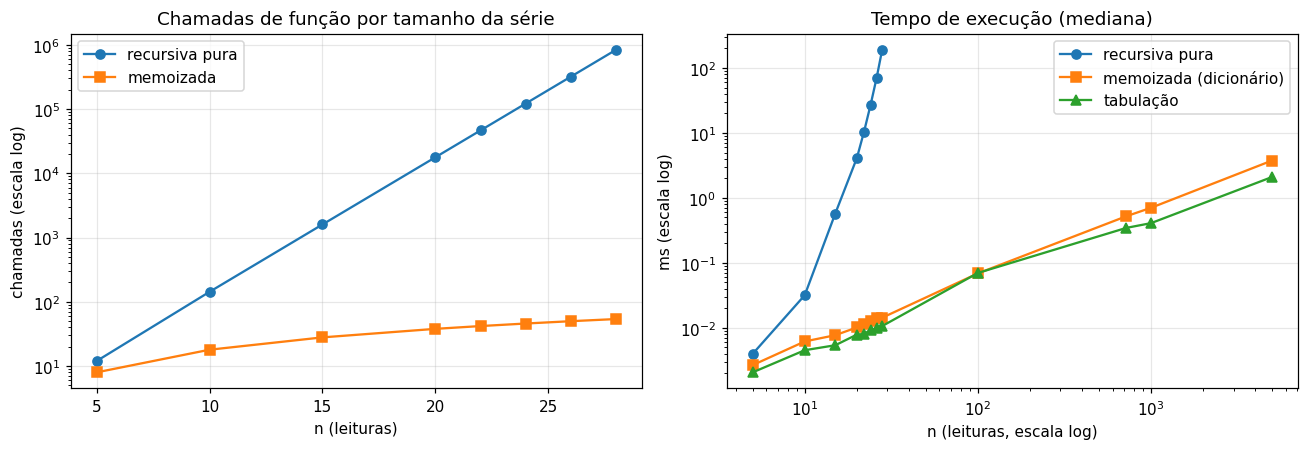

Crescimento das chamadas da recursiva a cada +2 leituras: [2.618 2.618 2.618] (φ² ≈ 2,618)


In [5]:
def medir(func, repeticoes=5):
    """Mediana do tempo de execução (ms) de func() em algumas repetições."""
    tempos = []
    for _ in range(repeticoes):
        t0 = time.perf_counter(); func(); tempos.append(time.perf_counter() - t0)
    return 1e3 * float(np.median(tempos))

rng = np.random.default_rng(7)
serie_longa = list(rng.choice(leituras.penalidade.values, size=6000, replace=True))

medicoes = []
for n in [5, 10, 15, 20, 22, 24, 26, 28]:
    p = serie_longa[:n]
    c = [0]; degradacao_recursiva(p, n - 1, c)
    cm = [0]; degradacao_memo(p, n - 1, {}, cm)
    medicoes.append({"n": n, "chamadas_rec": c[0], "chamadas_memo": cm[0],
                     "ms_rec": medir(lambda: degradacao_recursiva(p, n - 1), 3),
                     "ms_memo": medir(lambda: degradacao_memo(p, n - 1, {})),
                     "ms_tab": medir(lambda: degradacao_tabulacao(p))})
for n in [100, 720, 1000, 5000]:
    p = serie_longa[:n]
    cm = [0]; degradacao_memo(p, n - 1, {}, cm)
    medicoes.append({"n": n, "chamadas_rec": np.nan, "chamadas_memo": cm[0], "ms_rec": np.nan,
                     "ms_memo": medir(lambda: degradacao_memo(p, n - 1, {})),
                     "ms_tab": medir(lambda: degradacao_tabulacao(p))})
medicoes = pd.DataFrame(medicoes)
display(medicoes.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
m = medicoes.dropna(subset=["ms_rec"])
ax[0].semilogy(m.n, m.chamadas_rec, "o-", label="recursiva pura")
ax[0].semilogy(m.n, m.chamadas_memo, "s-", label="memoizada")
ax[0].set(title="Chamadas de função por tamanho da série", xlabel="n (leituras)", ylabel="chamadas (escala log)")
ax[0].legend()
ax[1].loglog(medicoes.n, medicoes.ms_rec, "o-", label="recursiva pura")
ax[1].loglog(medicoes.n, medicoes.ms_memo, "s-", label="memoizada (dicionário)")
ax[1].loglog(medicoes.n, medicoes.ms_tab, "^-", label="tabulação")
ax[1].set(title="Tempo de execução (mediana)", xlabel="n (leituras, escala log)", ylabel="ms (escala log)")
ax[1].legend()
plt.tight_layout(); plt.savefig(FIGURAS / "tempo_degradacao.png", bbox_inches="tight"); plt.show()

razao = m.set_index("n").chamadas_rec
print("Crescimento das chamadas da recursiva a cada +2 leituras:",
      (razao.loc[[24, 26, 28]].values / razao.loc[[22, 24, 26]].values).round(3), "(φ² ≈ 2,618)")

**Interpretação.**

- **Resultados idênticos.** As três versões produzem exatamente o mesmo $D$ nas 197 escadas. Memoização e tabulação mudam **o custo**, não **a resposta**.
- **Recursiva pura é exponencial.** O número de chamadas cresce 2,618 vezes a cada duas leituras a mais, exatamente $\varphi^2$. Só com 24 leituras diárias são 121 392 chamadas por escada, ou 24 milhões para a frota, contra 9 062 da memoizada.
- **Com telemetria real, só a tabulação serve.** Uma leitura por hora gera 720 leituras por escada em um mês. Com esse volume a recursão pura não termina, e a memoizada depende de aumentar o limite de pilha do Python. A tabulação processa as 720 leituras em fração de milissegundo, sem pilha. É a versão adotada no ranking.

### 1.5 Ranking das escadas por criticidade

A **criticidade** é a degradação acumulada na última leitura, $D(n-1)$. Aqui as classes podem usar **limites fixos**, porque a penalidade tem escala física: com penalidade constante $p$ e sem aceleração, $D$ converge para $p/(1-\alpha) \approx 6{,}7\,p$. Assim, $D \ge 200$ corresponde a manter cerca de 30 pontos de penalidade, ou seja, pelo menos uma variável no limite crítico.

| Classe | Degradação acumulada $D$ |
|---|---|
| Crítica | $D \ge 200$ |
| Alta | $100 \le D < 200$ |
| Média | $40 \le D < 100$ |
| Baixa | $D < 40$ |

In [6]:
def classe_criticidade(d):
    """Classe de criticidade a partir da degradação acumulada final."""
    if d >= 200: return "Crítica"
    if d >= 100: return "Alta"
    if d >= 40:  return "Média"
    return "Baixa"

ultimas = leituras.groupby("cd_escada").tail(1).set_index("cd_escada")
serie_D = {cd: degradacao_tabulacao(p) for cd, p in series_p.items()}

ranking = (pd.DataFrame({"cd_escada": list(serie_D), "criticidade": [s[-1] for s in serie_D.values()]})
           .merge(escadas[["cd_escada", "id_estacao"]], on="cd_escada"))
ranking["estacao"] = ranking.id_estacao.map(nomes_est)
ranking["classe"] = ranking.criticidade.apply(classe_criticidade)
ranking["penalidade_ultima"] = ranking.cd_escada.map(ultimas.penalidade)
ranking["componente_principal"] = ranking.cd_escada.map(ultimas.variavel_dominante)
ranking["hs_java"] = ranking.cd_escada.map(ultimas.hs_java)
ranking["situacao_java"] = ranking.cd_escada.map(ultimas.situacao_java)
ranking = ranking.sort_values("criticidade", ascending=False).reset_index(drop=True)
ranking.index = ranking.index + 1
ranking.index.name = "posição"
display(ranking.head(20).round(1))
print(ranking.classe.value_counts().reindex(["Crítica", "Alta", "Média", "Baixa"]).to_string())
print("\nSituação no Java × classe pelo SafeStair:")
display(pd.crosstab(ranking.situacao_java, ranking.classe).reindex(columns=["Crítica", "Alta", "Média", "Baixa"], fill_value=0))

,cd_escada,criticidade,id_estacao,estacao,classe,penalidade_ultima,componente_principal,hs_java,situacao_java
posição,,,,,,,,,
1,TVS-ER06,304.2,TVS,Terminal Vila Sônia,Crítica,56.1,vibracao_mm_s,43,INTERVENCAO RECOMENDADA
2,HIG-ER22,295.5,HIG,Higienópolis-Mackenzie,Crítica,57.8,vibracao_mm_s,43,INTERVENCAO RECOMENDADA
3,FRE-ER09,284.0,FRE,Oscar Freire,Crítica,51.8,vibracao_mm_s,65,INTERVENCAO RECOMENDADA
4,PIN-ER16,275.7,PIN,Pinheiros,Crítica,53.2,temperatura_c,70,INTERVENCAO RECOMENDADA
5,PIN-ER25,275.5,PIN,Pinheiros,Crítica,51.6,vibracao_mm_s,55,INTERVENCAO RECOMENDADA
6,PIN-ER22,262.9,PIN,Pinheiros,Crítica,53.7,vibracao_mm_s,55,INTERVENCAO RECOMENDADA
7,PTA-ER02,258.5,PTA,Paulista,Crítica,51.1,temperatura_c,70,INTERVENCAO RECOMENDADA
8,HIG-ER08,249.1,HIG,Higienópolis-Mackenzie,Crítica,49.7,temperatura_c,70,INTERVENCAO RECOMENDADA
9,FRE-ER04,248.6,FRE,Oscar Freire,Crítica,52.5,temperatura_c,70,INTERVENCAO RECOMENDADA


classe
Crítica     17
Alta        26
Média       24
Baixa      130

Situação no Java × classe pelo SafeStair:


classe,Crítica,Alta,Média,Baixa
situacao_java,,,,
ATENCAO,0,8,4,3
INTERVENCAO RECOMENDADA,17,9,0,0
OPERANDO NORMALMENTE,0,9,20,127


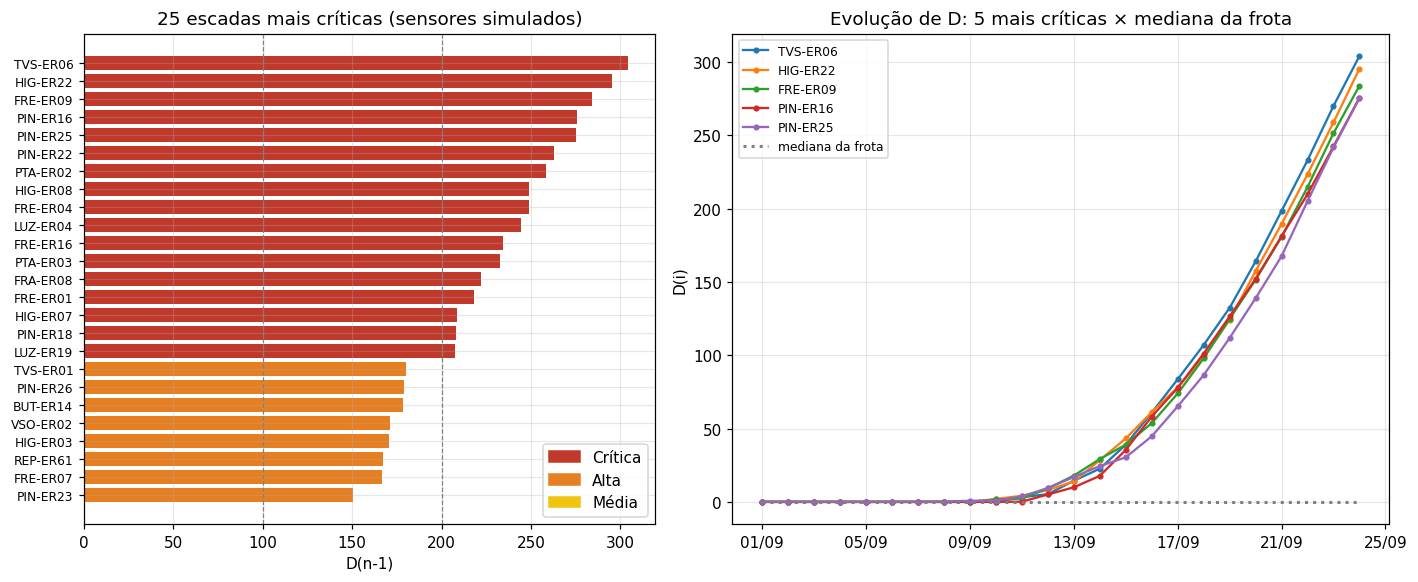

In [7]:
cores = {"Crítica": "#c0392b", "Alta": "#e67e22", "Média": "#f1c40f", "Baixa": "#27ae60"}
from matplotlib.patches import Patch
fig, ax = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1, 1.15]})
r = ranking.head(25).iloc[::-1]
ax[0].barh(r.cd_escada, r.criticidade, color=[cores[c] for c in r.classe])
for lim in (100, 200):
    ax[0].axvline(lim, color="grey", ls="--", lw=0.8)
ax[0].set(title="25 escadas mais críticas (sensores simulados)", xlabel="D(n-1)")
ax[0].tick_params(axis="y", labelsize=8)
ax[0].legend(handles=[Patch(color=cores[c], label=c) for c in ["Crítica", "Alta", "Média"]], loc="lower right")
datas = leituras.dt_leitura.drop_duplicates().sort_values()
for cd in ranking.cd_escada.head(5):
    ax[1].plot(datas.values, serie_D[cd], marker=".", label=cd)
mediana = np.median(np.array(list(serie_D.values())), axis=0)
ax[1].plot(datas.values, mediana, color="grey", ls=":", lw=2, label="mediana da frota")
ax[1].set(title="Evolução de D: 5 mais críticas × mediana da frota", ylabel="D(i)")
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGURAS / "ranking_criticidade.png", bbox_inches="tight"); plt.show()

**Interpretação.**

- **Coerência com o Java:** as 17 escadas críticas também aparecem como "INTERVENCAO RECOMENDADA" no `ManutencaoService`. Os dois modelos concordam nos casos graves.
- **O ranking desempata o que o Java iguala:** 26 escadas recebem "intervenção recomendada" do Java. A degradação acumulada separa as 17 críticas das 9 que são só Alta e dá a ordem de atendimento.
- **O ranking antecipa o que o Java não vê:** 9 escadas estão "OPERANDO NORMALMENTE" para o Java, mas são Alta para o SafeStair. Em 6 delas o problema dominante é a **velocidade**, que cai por atrito enquanto a corrente sobe, e o Java ainda não usa essas variáveis. As outras 3 têm temperatura subindo dentro da faixa de atenção, mas com tendência de piora que o termo de aceleração capta. Isso é manutenção **preditiva**: agir antes de a regra em degrau disparar.
- **Componentes:** nas críticas dominam vibração (9) e temperatura (8), enquanto nível de óleo lidera entre as de classe Alta (10). Isso orienta a ordem de serviço.
- **Limites:** como os perfis de falha foram sorteados, **a distribuição por estação não tem significado**. O que este notebook demonstra é o método, não o diagnóstico da frota, que está no notebook principal.

---
## Parte 2 — Rede de estações como grafo

### 2.1 Modelagem

- **Vértices:** 19 locais das linhas operadas pela Motiva e 1 **base de manutenção** no Pátio Vila Sônia. São as 11 estações da Linha 4-Amarela (ViaQuatro) mais o Terminal Vila Sônia, que são os 12 locais com escadas no dataset, e 7 estações das Linhas 9-Esmeralda e 5-Lilás (ViaMobilidade), ligadas à Linha 4 por Pinheiros.
- **Ids = códigos do SAP:** os vértices da Linha 4 usam os mesmos códigos do campo Local de Instalação (PTA = Paulista, FRE = Oscar Freire, FAL = Faria Lima, MBI = São Paulo-Morumbi, TVS = Terminal Vila Sônia). É isso que liga cada escada do dataset a um vértice.
- **Arestas:** trechos entre estações, com peso em **minutos de deslocamento** da equipe. Trechos que começam em estações de integração (Pinheiros, Santo Amaro) já incluem a baldeação. Na 5-Lilás e na 9-Esmeralda, alguns trechos agregam estações intermediárias não modeladas.
- **Trechos rodoviários:** a equipe também pode sair da base de van. Esses trechos têm **poucas arestas, mas tempo maior** no trânsito, o que faz o BFS e o Dijkstra discordarem.
- **Estrutura:** lista de adjacência (`dict` de vértice para lista de vizinhos), grafo não direcionado.

Coordenadas e tempos são aproximados, adequados para o exercício e não para operação real.

In [8]:
def construir_lista_adjacencia(rede):
    """Monta a lista de adjacência não direcionada a partir do JSON da rede.

    Args:
        rede (dict): conteúdo de rede_estacoes.json.

    Returns:
        dict[str, list[tuple[str, float, str]]]: vértice -> [(vizinho, minutos, modo), ...].
    """
    adj = {v["id"]: [] for v in rede["vertices"]}
    for a in rede["arestas"]:
        adj[a["origem"]].append((a["destino"], a["minutos"], a["modo"]))
        adj[a["destino"]].append((a["origem"], a["minutos"], a["modo"]))
    for v in adj:
        adj[v].sort()
    return adj

ADJ = construir_lista_adjacencia(rede)
BASE = rede["base"]
COORD = {v["id"]: (v["lat"], v["lon"]) for v in rede["vertices"]}

for v, viz in ADJ.items():
    print(f"{v:>4} -> " + ", ".join(f"{u}({w} min, {m})" for u, w, m in viz))

sem_estacao = set(escadas.id_estacao) - set(ADJ)
print("\nEscadas ligadas a estações do grafo:", len(escadas) - len(sem_estacao), "de", len(escadas))
assert not sem_estacao, f"Escadas sem estação no grafo: {sem_estacao}"
print("Escadas por estação:", escadas.groupby("id_estacao").size().to_dict())

 LUZ -> REP(2 min, metro)
 REP -> HIG(2 min, metro), LUZ(2 min, metro)
 HIG -> PTA(2 min, metro), REP(2 min, metro)
 PTA -> BASE(35 min, rodovia), FRE(2 min, metro), HIG(2 min, metro)
 FRE -> FRA(2 min, metro), PTA(2 min, metro)
 FRA -> FAL(2 min, metro), FRE(2 min, metro)
 FAL -> FRA(2 min, metro), PIN(2 min, metro)
 PIN -> BUT(2 min, metro), CJD(9 min, trem), FAL(2 min, metro)
 BUT -> BASE(14 min, rodovia), MBI(3 min, metro), PIN(2 min, metro)
 MBI -> BUT(3 min, metro), VSO(3 min, metro)
 VSO -> BASE(6 min, rodovia), MBI(3 min, metro), TVS(3 min, a pé)
 TVS -> VSO(3 min, a pé)
 CJD -> PIN(9 min, trem), VOL(3 min, trem)
 VOL -> BER(3 min, trem), CJD(3 min, trem)
 BER -> SAM(9 min, trem), VOL(3 min, trem)
 SAM -> BASE(25 min, rodovia), BER(9 min, trem), CBE(15 min, metro)
 CBE -> MOE(4 min, metro), SAM(15 min, metro)
 MOE -> CBE(4 min, metro), SCZ(6 min, metro)
 SCZ -> MOE(6 min, metro)
BASE -> BUT(14 min, rodovia), PTA(35 min, rodovia), SAM(25 min, rodovia), VSO(6 min, rodovia)

Escad

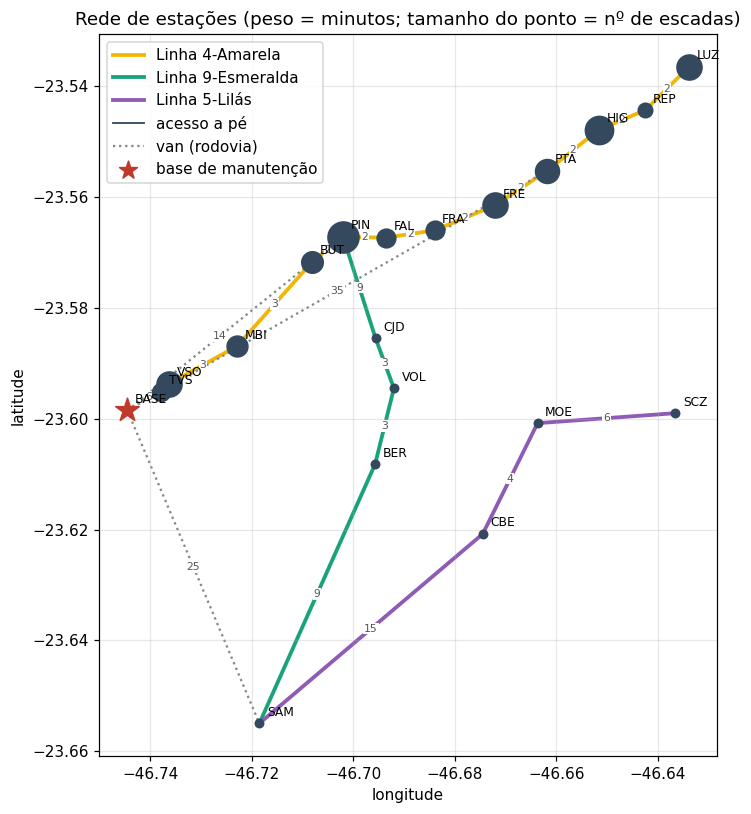

In [9]:
estilo = {"4-Amarela": dict(color="#f2b705", lw=2.5, ls="-"), "9-Esmeralda": dict(color="#1aa37a", lw=2.5, ls="-"),
          "5-Lilás": dict(color="#8e5bb5", lw=2.5, ls="-"), "acesso": dict(color="#34495e", lw=1.2, ls="-"),
          "rodovia": dict(color="#7f8c8d", lw=1.5, ls=":")}
fig, ax = plt.subplots(figsize=(9, 7.5))
for a in rede["arestas"]:
    (y1, x1), (y2, x2) = COORD[a["origem"]], COORD[a["destino"]]
    ax.plot([x1, x2], [y1, y2], **estilo[a["linha"]], zorder=1)
    ax.text((x1 + x2) / 2, (y1 + y2) / 2, f'{a["minutos"]}', fontsize=7, color="#555",
            ha="center", va="center", bbox=dict(fc="white", ec="none", pad=0.5), zorder=2)
qtd = escadas.groupby("id_estacao").size()
for v in rede["vertices"]:
    y, x = v["lat"], v["lon"]
    if v["id"] == BASE:
        ax.scatter(x, y, s=260, marker="*", color="#c0392b", zorder=3)
    else:
        ax.scatter(x, y, s=30 + 12 * qtd.get(v["id"], 0), color="#34495e", zorder=3)
    ax.annotate(v["id"], (x, y), xytext=(5, 5), textcoords="offset points", fontsize=8)
for nome, e in estilo.items():
    ax.plot([], [], **e, label={"rodovia": "van (rodovia)", "acesso": "acesso a pé"}.get(nome, f"Linha {nome}"))
ax.scatter([], [], marker="*", s=150, color="#c0392b", label="base de manutenção")
ax.legend(loc="upper left"); ax.set(title="Rede de estações (peso = minutos; tamanho do ponto = nº de escadas)",
                                    xlabel="longitude", ylabel="latitude")
ax.set_aspect(1 / math.cos(math.radians(-23.58)))
plt.tight_layout(); plt.savefig(FIGURAS / "rede_estacoes.png", bbox_inches="tight"); plt.show()

### 2.2 BFS (menos trechos) e Dijkstra (menor tempo)

- **BFS** explora o grafo em camadas e encontra o caminho com **menos arestas**, ignorando os pesos. Complexidade $O(V + E)$.
- **Dijkstra** usa uma fila de prioridade (heap) para sempre expandir o vértice de menor tempo acumulado e encontra o caminho de **menor tempo**. Complexidade $O((V + E)\log V)$.
- Os dois guardam o **predecessor** de cada vértice, e `reconstruir_rota` volta do destino até a origem para montar o caminho.

In [10]:
def bfs(adj, origem):
    """Busca em largura a partir da origem.

    Args:
        adj (dict): lista de adjacência.
        origem (str): vértice inicial.

    Returns:
        tuple[dict, dict]: (trechos até cada vértice, predecessor de cada vértice).
    """
    trechos, pai = {origem: 0}, {origem: None}
    fila = deque([origem])
    while fila:
        v = fila.popleft()
        for u, _, _ in adj[v]:
            if u not in trechos:
                trechos[u] = trechos[v] + 1
                pai[u] = v
                fila.append(u)
    return trechos, pai


def dijkstra(adj, origem, destino=None):
    """Menor tempo a partir da origem (Dijkstra com heap).

    Args:
        adj (dict): lista de adjacência com pesos em minutos.
        origem (str): vértice inicial.
        destino (str, opcional): se informado, para ao fechar o destino.

    Returns:
        tuple[dict, dict, int]: (tempo até cada vértice, predecessor, vértices expandidos).
    """
    dist, pai = {origem: 0.0}, {origem: None}
    heap, fechados, expandidos = [(0.0, origem)], set(), 0
    while heap:
        d, v = heapq.heappop(heap)
        if v in fechados:
            continue
        fechados.add(v); expandidos += 1
        if v == destino:
            break
        for u, w, _ in adj[v]:
            nd = d + w
            if nd < dist.get(u, math.inf):
                dist[u], pai[u] = nd, v
                heapq.heappush(heap, (nd, u))
    return dist, pai, expandidos


def reconstruir_rota(pai, origem, destino):
    """Reconstrói o caminho origem -> destino seguindo os predecessores.

    Returns:
        list[str]: vértices do caminho (vazia se o destino não for alcançável).
    """
    if destino not in pai:
        return []
    rota, v = [], destino
    while v is not None:
        rota.append(v); v = pai[v]
    rota.reverse()
    return rota if rota[0] == origem else []


def tempo_rota(adj, rota):
    """Soma dos minutos dos trechos de uma rota."""
    return sum(next(w for u, w, _ in adj[a] if u == b) for a, b in zip(rota, rota[1:]))


trechos_bfs, pai_bfs = bfs(ADJ, BASE)
dist_dij, pai_dij, _ = dijkstra(ADJ, BASE)

linhas = []
for v in sorted(ADJ, key=lambda x: dist_dij[x]):
    if v == BASE:
        continue
    rb, rd = reconstruir_rota(pai_bfs, BASE, v), reconstruir_rota(pai_dij, BASE, v)
    linhas.append({"estação": nomes_est[v], "rota BFS": " → ".join(rb), "trechos BFS": len(rb) - 1,
                   "min BFS": tempo_rota(ADJ, rb), "rota Dijkstra": " → ".join(rd),
                   "trechos Dijkstra": len(rd) - 1, "min Dijkstra": dist_dij[v]})
rotas = pd.DataFrame(linhas)
rotas["ganho (min)"] = rotas["min BFS"] - rotas["min Dijkstra"]
display(rotas)
dif = rotas[rotas["ganho (min)"] > 0]
print(f"Estações em que o BFS escolhe uma rota mais lenta: {len(dif)} de {len(rotas)}; "
      f"ganho médio do Dijkstra nelas: {dif['ganho (min)'].mean():.1f} min; máximo: {dif['ganho (min)'].max():.0f} min")

,estação,rota BFS,trechos BFS,min BFS,rota Dijkstra,trechos Dijkstra,min Dijkstra,ganho (min)
0,Vila Sônia,BASE → VSO,1,6,BASE → VSO,1,6.0,0.0
1,São Paulo-Morumbi,BASE → BUT → MBI,2,17,BASE → VSO → MBI,2,9.0,8.0
2,Terminal Vila Sônia,BASE → VSO → TVS,2,9,BASE → VSO → TVS,2,9.0,0.0
3,Butantã,BASE → BUT,1,14,BASE → VSO → MBI → BUT,3,12.0,2.0
4,Pinheiros,BASE → BUT → PIN,2,16,BASE → VSO → MBI → BUT → PIN,4,14.0,2.0
5,Faria Lima,BASE → BUT → PIN → FAL,3,18,BASE → VSO → MBI → BUT → PIN → FAL,5,16.0,2.0
6,Fradique Coutinho,BASE → PTA → FRE → FRA,3,39,BASE → VSO → MBI → BUT → PIN → FAL → FRA,6,18.0,21.0
7,Oscar Freire,BASE → PTA → FRE,2,37,BASE → VSO → MBI → BUT → PIN → FAL → FRA → FRE,7,20.0,17.0
8,Paulista,BASE → PTA,1,35,BASE → VSO → MBI → BUT → PIN → FAL → FRA → FRE → PTA,8,22.0,13.0
9,Cidade Jardim,BASE → BUT → PIN → CJD,3,25,BASE → VSO → MBI → BUT → PIN → CJD,5,23.0,2.0


Estações em que o BFS escolhe uma rota mais lenta: 13 de 19; ganho médio do Dijkstra nelas: 9.4 min; máximo: 21 min


**Interpretação.**

- Em 13 das 19 estações o BFS escolhe uma rota mais lenta (em média 9,4 min a mais, até 21 min). Nas estações da Linha 4 perto da Paulista, o **BFS escolhe a van** (BASE → PTA), porque é um único trecho, mas ela leva 35 minutos no trânsito; o **Dijkstra prefere o metrô** desde Vila Sônia, com mais trechos e bem menos tempo (22 min até a Paulista). É a diferença entre "menos trechos" e "menor tempo".
- Entre caminhos com o mesmo número de trechos, o BFS fica com o primeiro que encontra, sem olhar o tempo: para São Paulo-Morumbi ele vai pela van até o Butantã (17 min) em vez da van até Vila Sônia (9 min).
- Quando a van também é a opção mais rápida, como para Santo Amaro (25 min de van contra cerca de 38 min de metrô e trem), os dois algoritmos concordam.
- Para o planejamento de manutenção o critério correto é o **tempo**, por isso o `planejar_turno` usa Dijkstra. O BFS serve como referência de quantas baldeações e trocas de modal a rota exige.

---
## Parte 3 — Otimização de rotas com A*

### 3.1 Heurística

O A\* expande primeiro os vértices com menor $f(n) = g(n) + h(n)$, em que $g$ é o tempo já gasto e $h$ uma **estimativa do tempo restante**. Usamos:

$$
h(n) = \frac{\text{distância em linha reta}(n,\ \text{destino})}{v_{\max}}, \qquad
v_{\max} = \max_{(a,b) \in E} \frac{\text{distância em linha reta}(a,b)}{\text{minutos}(a,b)}
$$

A distância em linha reta é calculada pela fórmula de haversine sobre as coordenadas das estações, e $v_{\max}$ é a **maior velocidade efetiva** observada em algum trecho da própria rede.

**Por que é admissível (nunca superestima):** em qualquer trecho, $\text{minutos}(a,b) \ge \text{dist}(a,b)/v_{\max}$ pela definição de $v_{\max}$. Somando ao longo de qualquer caminho de $n$ até o destino e usando a desigualdade triangular (a linha reta é o menor percurso), o tempo real é sempre $\ge \text{dist}(n,\text{destino})/v_{\max} = h(n)$. **Consistência** sai do mesmo argumento aplicado a um único trecho: $h(a) \le \text{minutos}(a,b) + h(b)$. Com $h$ consistente, o A\* retorna o caminho ótimo sem reabrir vértices.

Usar a velocidade máxima da própria rede, em vez de um valor fixo como 80 km/h, deixa $h$ o mais informativa possível sem perder a garantia. Para comparar, testamos também $h_{80}$ (80 km/h fixos, mais fraca) e $h = 0$ (que transforma o A\* no próprio Dijkstra).

In [11]:
def haversine_km(a, b):
    """Distância em linha reta (km) entre dois vértices, pelas coordenadas."""
    (la1, lo1), (la2, lo2) = COORD[a], COORD[b]
    la1, lo1, la2, lo2 = map(math.radians, (la1, lo1, la2, lo2))
    h = math.sin((la2 - la1) / 2) ** 2 + math.cos(la1) * math.cos(la2) * math.sin((lo2 - lo1) / 2) ** 2
    return 2 * 6371.0 * math.asin(math.sqrt(h))

VMAX = max(haversine_km(a["origem"], a["destino"]) / a["minutos"] for a in rede["arestas"])  # km/min
trecho_vmax = max(rede["arestas"], key=lambda a: haversine_km(a["origem"], a["destino"]) / a["minutos"])
print(f"v_max da rede = {VMAX:.3f} km/min = {VMAX * 60:.1f} km/h "
      f"(trecho {trecho_vmax['origem']}–{trecho_vmax['destino']})")


def heuristica_rede(destino):
    """h(n) = distância em linha reta até o destino / v_max da rede (minutos)."""
    return lambda n: haversine_km(n, destino) / VMAX

def heuristica_80kmh(destino):
    """h(n) com velocidade fixa de 80 km/h (admissível, porém mais fraca)."""
    return lambda n: haversine_km(n, destino) / (80 / 60)

def heuristica_zero(destino):
    """h(n) = 0: o A* se reduz ao Dijkstra."""
    return lambda n: 0.0


def a_estrela(adj, origem, destino, h):
    """Busca A* do caminho de menor tempo.

    Args:
        adj (dict): lista de adjacência com pesos em minutos.
        origem (str): vértice inicial.
        destino (str): vértice final.
        h (callable): heurística h(n) em minutos, admissível e consistente.

    Returns:
        tuple[float, list[str], int]: (tempo mínimo, rota, vértices expandidos).
    """
    g, pai = {origem: 0.0}, {origem: None}
    heap, fechados, expandidos = [(h(origem), 0.0, origem)], set(), 0
    while heap:
        _, gv, v = heapq.heappop(heap)
        if v in fechados:
            continue
        fechados.add(v); expandidos += 1
        if v == destino:
            return gv, reconstruir_rota(pai, origem, destino), expandidos
        for u, w, _ in adj[v]:
            ng = gv + w
            if ng < g.get(u, math.inf):
                g[u], pai[u] = ng, v
                heapq.heappush(heap, (ng + h(u), ng, u))
    return math.inf, [], expandidos


# Verificação numérica de admissibilidade e consistência, para todos os pares (n, destino)
viol_adm = viol_cons = 0
for destino in ADJ:
    real, _, _ = dijkstra(ADJ, destino)
    h = heuristica_rede(destino)
    viol_adm += sum(h(n) > real[n] + 1e-9 for n in ADJ)
    viol_cons += sum(h(a) > w + h(b) + 1e-9 for a in ADJ for b, w, _ in ADJ[a])
print("Violações de admissibilidade:", viol_adm, "| violações de consistência:", viol_cons)

v_max da rede = 0.755 km/min = 45.3 km/h (trecho BUT–MBI)
Violações de admissibilidade: 0 | violações de consistência: 0


### 3.2 A\* comparado ao Dijkstra na rede de estações

Para uma comparação justa, o Dijkstra também para assim que fecha o destino. Medimos o tempo mínimo encontrado, os **vértices expandidos** e o tempo de execução (mediana de 200 repetições) da base até cada estação.

In [12]:
def medir_us(func, rep=200):
    """Mediana do tempo de execução de func() em microssegundos."""
    t = []
    for _ in range(rep):
        t0 = time.perf_counter(); func(); t.append(time.perf_counter() - t0)
    return 1e6 * float(np.median(t))

linhas = []
for destino in [v for v in ADJ if v != BASE]:
    d_dij, _, exp_dij = dijkstra(ADJ, BASE, destino)
    c_a, rota_a, exp_a = a_estrela(ADJ, BASE, destino, heuristica_rede(destino))
    _, _, exp_80 = a_estrela(ADJ, BASE, destino, heuristica_80kmh(destino))
    linhas.append({"destino": destino, "min Dijkstra": d_dij[destino], "min A*": c_a,
                   "exp Dijkstra": exp_dij, "exp A* (v_max)": exp_a, "exp A* (80 km/h)": exp_80,
                   "µs Dijkstra": medir_us(lambda: dijkstra(ADJ, BASE, destino)),
                   "µs A*": medir_us(lambda: a_estrela(ADJ, BASE, destino, heuristica_rede(destino)))})
astar_rede = pd.DataFrame(linhas)
display(astar_rede.round(1))
print("Mesmo tempo ótimo em todos os destinos:", np.allclose(astar_rede["min Dijkstra"], astar_rede["min A*"]))
tot = astar_rede[["exp Dijkstra", "exp A* (v_max)", "exp A* (80 km/h)"]].sum()
print(f"Expansões totais — Dijkstra: {tot.iloc[0]} | A* v_max: {tot.iloc[1]} ({100 * (1 - tot.iloc[1] / tot.iloc[0]):.0f}% a menos)"
      f" | A* 80 km/h: {tot.iloc[2]} ({100 * (1 - tot.iloc[2] / tot.iloc[0]):.0f}% a menos)")

,destino,min Dijkstra,min A*,exp Dijkstra,exp A* (v_max),exp A* (80 km/h),µs Dijkstra,µs A*
0,LUZ,28.0,28.0,16,13,13,10.3,23.6
1,REP,26.0,26.0,14,12,12,9.6,22.7
2,HIG,24.0,24.0,12,11,11,8.1,20.8
3,PTA,22.0,22.0,10,10,10,7.2,19.4
4,FRE,20.0,20.0,9,9,9,8.2,17.9
5,FRA,18.0,18.0,8,8,8,6.2,18.2
6,FAL,16.0,16.0,7,6,7,5.3,17.4
7,PIN,14.0,14.0,6,5,6,4.4,12.4
8,BUT,12.0,12.0,5,4,5,3.7,10.3
9,MBI,9.0,9.0,3,3,3,2.6,9.0


Mesmo tempo ótimo em todos os destinos: True
Expansões totais — Dijkstra: 209 | A* v_max: 180 (14% a menos) | A* 80 km/h: 189 (10% a menos)


### 3.3 Escalabilidade: uma malha urbana maior

A rede do exercício tem só 20 vértices, então qualquer algoritmo termina em microssegundos. Para ver como a diferença cresce, geramos uma **malha urbana sintética** de 60 × 60 cruzamentos (3 600 vértices, espaçamento de 0,5 km) com tempos de trecho entre 1× e 2,5× o tempo a 30 km/h (trânsito variável). A heurística é a mesma ideia: distância em linha reta dividida pela maior velocidade efetiva da malha. Rodamos 40 pares origem–destino aleatórios.

Mesmo tempo ótimo em todos os pares: True


,exp Dijkstra,exp A*,ms Dijkstra,ms A*
mean,1807.8,946.8,2.9,1.9
median,1802.5,801.0,2.5,1.4


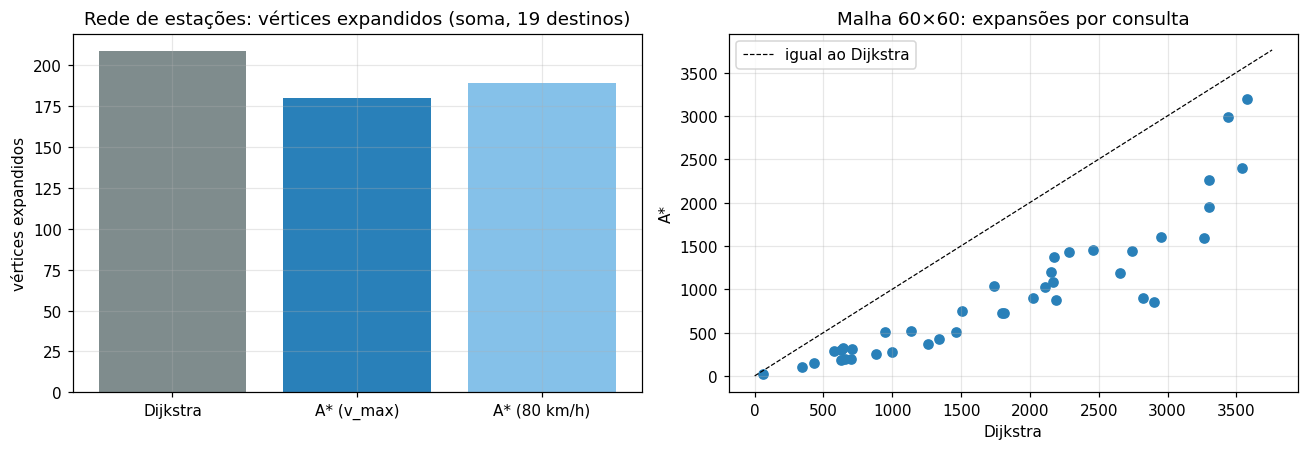

In [13]:
def malha_urbana(lado=60, passo_km=0.5, semente=3):
    """Cria uma malha urbana sintética (lista de adjacência + coordenadas em km)."""
    rnd = random.Random(semente)
    coord = {(i, j): (i * passo_km, j * passo_km) for i in range(lado) for j in range(lado)}
    adj = {v: [] for v in coord}
    for (i, j) in coord:
        for di, dj in ((1, 0), (0, 1)):
            u = (i + di, j + dj)
            if u in coord:
                w = passo_km / 0.5 * rnd.uniform(1.0, 2.5)   # 0,5 km/min = 30 km/h
                adj[(i, j)].append((u, w, "rua")); adj[u].append(((i, j), w, "rua"))
    return adj, coord

ADJ_M, COORD_M = malha_urbana()
VMAX_M = max(math.dist(COORD_M[a], COORD_M[b]) / w for a in ADJ_M for b, w, _ in ADJ_M[a])
rnd = random.Random(11)
pares = [(rnd.choice(list(ADJ_M)), rnd.choice(list(ADJ_M))) for _ in range(40)]

res = []
for o, d in pares:
    hm = lambda n, d=d: math.dist(COORD_M[n], COORD_M[d]) / VMAX_M
    dd, _, ed = dijkstra(ADJ_M, o, d)
    ca, _, ea = a_estrela(ADJ_M, o, d, hm)
    res.append({"min Dijkstra": dd[d], "min A*": ca, "exp Dijkstra": ed, "exp A*": ea,
                "ms Dijkstra": medir_us(lambda: dijkstra(ADJ_M, o, d), 5) / 1e3,
                "ms A*": medir_us(lambda: a_estrela(ADJ_M, o, d, hm), 5) / 1e3})
malha = pd.DataFrame(res)
print("Mesmo tempo ótimo em todos os pares:", np.allclose(malha["min Dijkstra"], malha["min A*"]))
resumo = malha[["exp Dijkstra", "exp A*", "ms Dijkstra", "ms A*"]].agg(["mean", "median"]).round(1)
display(resumo)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].bar(["Dijkstra", "A* (v_max)", "A* (80 km/h)"], tot.values, color=["#7f8c8d", "#2980b9", "#85c1e9"])
ax[0].set(title="Rede de estações: vértices expandidos (soma, 19 destinos)", ylabel="vértices expandidos")
ax[1].scatter(malha["exp Dijkstra"], malha["exp A*"], color="#2980b9")
lim = malha["exp Dijkstra"].max() * 1.05
ax[1].plot([0, lim], [0, lim], "k--", lw=0.8, label="igual ao Dijkstra")
ax[1].set(title="Malha 60×60: expansões por consulta", xlabel="Dijkstra", ylabel="A*")
ax[1].legend()
plt.tight_layout(); plt.savefig(FIGURAS / "astar_vs_dijkstra.png", bbox_inches="tight"); plt.show()

**Interpretação.**

- **Mesmo resultado, menos trabalho.** O A\* encontrou exatamente o mesmo tempo mínimo que o Dijkstra em todos os destinos, como garante a heurística admissível e consistente (verificada numericamente acima, sem nenhuma violação).
- **Na rede das estações o ganho em expansões é modesto e não vira ganho de tempo.** O A\* expande 14% menos vértices no total (180 contra 209), com o maior efeito nos destinos da Linha 9 (Santo Amaro: 6 expansões contra 13), porque deixa de explorar o lado da rede que se afasta do destino. Mesmo assim, em tempo de relógio ele leva cerca de 2 vezes mais microssegundos: calcular a haversine em cada vértice custa mais do que expandir os poucos vértices economizados em um grafo de 20 vértices.
- **A heurística mais informada ganha.** Usar a $v_{\max}$ da própria rede expande menos que os 80 km/h fixos, porque estima o tempo restante com mais precisão sem deixar de ser admissível.
- **Na malha de 3 600 vértices o A\* mostra a vantagem real:** na mediana expande 801 vértices contra 1 803 do Dijkstra (55% a menos) e também roda mais rápido (veja a tabela acima; os milissegundos variam um pouco a cada execução, as expansões não). O Dijkstra cresce em círculo a partir da origem, enquanto o A\* avança na direção do alvo.
- **Conclusão para o SafeStair:** com a rede atual, Dijkstra a partir da base (uma única execução calcula todas as rotas) é suficiente e mais simples. O A\* passa a compensar quando a rede incluir todas as estações e acessos viários das concessões da Motiva e as consultas forem ponto a ponto, como no replanejamento de um técnico já em campo.

---
## Parte 4 — Plano de manutenção: `planejar_turno(base, horas)`

**Regras:**

1. Entram no plano as escadas de classe **Crítica e Alta**; as demais seguem em monitoramento.
2. **Prioridade por classe:** nenhuma escada de uma classe é atendida antes das que cabem no turno da classe acima.
3. **Dentro da mesma classe:** primeiro as outras escadas da estação onde a equipe já está (deslocamento zero); depois, a de maior criticidade, onde quer que esteja. O caminho até ela é o de menor tempo (Dijkstra).
4. Uma escada só entra se o deslocamento + o serviço + **o retorno à base** ainda couberem no turno. Se não couber, fica como pendente e o algoritmo tenta a próxima.
5. **Tempo de serviço estimado por classe:** Crítica 90 min e Alta 60 min. Sem histórico de reparos nesta versão, não há como estimar por escada, como faz o notebook principal.

Os tempos entre estações vêm de uma tabela de menores tempos (Dijkstra a partir de cada vértice), e as rotas são reconstruídas com `reconstruir_rota`.

In [14]:
ORDEM_CLASSES = ["Crítica", "Alta"]

# Tempo de serviço estimado por classe (minutos)
TEMPO_SERVICO = {"Crítica": 90, "Alta": 60}
ranking["servico_min"] = ranking.classe.map(TEMPO_SERVICO)

# Menores tempos e predecessores de todos para todos (uma execução de Dijkstra por vértice)
TODOS_DIJ = {v: dijkstra(ADJ, v)[:2] for v in ADJ}


def planejar_turno(base, horas, ranking=None, adj=None, inicio="08:00"):
    """Indica quais escadas atender no turno, em que ordem e por qual caminho.

    Args:
        base (str): id do vértice de onde a equipe sai e para onde volta (ex.: 'BASE').
        horas (float): duração do turno em horas.
        ranking (pd.DataFrame, opcional): ranking de criticidade (padrão: o calculado na Parte 1).
        adj (dict, opcional): lista de adjacência (padrão: a rede de estações).
        inicio (str): horário de início do turno, 'HH:MM'.

    Returns:
        tuple[pd.DataFrame, dict]: (plano de visitas em ordem, resumo do turno).
    """
    ranking = RANKING_PADRAO if ranking is None else ranking
    adj = ADJ if adj is None else adj
    tempos = TODOS_DIJ if adj is ADJ else {v: dijkstra(adj, v)[:2] for v in adj}
    orcamento = horas * 60
    h0, m0 = map(int, inicio.split(":"))
    relogio = lambda minutos: f"{(h0 * 60 + m0 + int(round(minutos))) // 60 % 24:02d}:{(m0 + int(round(minutos))) % 60:02d}"

    posicao, t, plano, pendentes = base, 0.0, [], []
    for classe in ORDEM_CLASSES:
        restantes = ranking[ranking.classe == classe].copy()
        while not restantes.empty:
            dist_atual = tempos[posicao][0]
            restantes["desloc"] = restantes.id_estacao.map(dist_atual)
            restantes["volta"] = restantes.id_estacao.map(lambda e: tempos[e][0][base])
            restantes["cabe"] = t + restantes.desloc + restantes.servico_min + restantes.volta <= orcamento
            viaveis = restantes[restantes.cabe]
            if viaveis.empty:
                pendentes += restantes.cd_escada.tolist()
                break
            prox = (viaveis.assign(outra_estacao=viaveis.desloc > 0)
                    .sort_values(["outra_estacao", "criticidade"], ascending=[True, False]).iloc[0])
            rota = reconstruir_rota(tempos[posicao][1], posicao, prox.id_estacao)
            chegada = t + prox.desloc
            plano.append({"ordem": len(plano) + 1, "escada": prox.cd_escada, "estação": prox.estacao,
                          "classe": classe, "criticidade": round(prox.criticidade, 1),
                          "componente": prox.componente_principal,
                          "rota": " → ".join(rota) if len(rota) > 1 else "(mesma estação)",
                          "desloc. (min)": prox.desloc, "chegada": relogio(chegada),
                          "serviço (min)": prox.servico_min, "término": relogio(chegada + prox.servico_min)})
            t = chegada + prox.servico_min
            posicao = prox.id_estacao
            restantes = restantes[restantes.cd_escada != prox.cd_escada]

    volta = tempos[posicao][0][base]
    rota_volta = reconstruir_rota(tempos[posicao][1], posicao, base)
    total = t + volta
    resumo = {"turno (min)": orcamento, "escadas atendidas": len(plano),
              "deslocamento (min)": sum(p["desloc. (min)"] for p in plano) + volta,
              "serviço (min)": sum(p["serviço (min)"] for p in plano),
              "retorno": " → ".join(rota_volta) + f" ({volta:.0f} min, chegada {relogio(total)})",
              "ocupação do turno": f"{100 * total / orcamento:.0f}%",
              "pendentes": pendentes}
    return pd.DataFrame(plano).set_index("ordem") if plano else pd.DataFrame(), resumo


RANKING_PADRAO = ranking.copy()
print("Escadas candidatas por classe:", ranking[ranking.classe.isin(ORDEM_CLASSES)].classe.value_counts().to_dict())

Escadas candidatas por classe: {'Alta': 26, 'Crítica': 17}


In [15]:
plano8, resumo8 = planejar_turno("BASE", 8)
print("TURNO DE 8 HORAS (início 08:00)")
display(plano8)
for k, v in resumo8.items():
    print(f"  {k}: {v}")

TURNO DE 8 HORAS (início 08:00)


,escada,estação,classe,criticidade,componente,rota,desloc. (min),chegada,serviço (min),término
ordem,,,,,,,,,,
1,TVS-ER06,Terminal Vila Sônia,Crítica,304.2,vibracao_mm_s,BASE → VSO → TVS,9.0,08:09,90.0,09:39
2,HIG-ER22,Higienópolis-Mackenzie,Crítica,295.5,vibracao_mm_s,TVS → VSO → MBI → BUT → PIN → FAL → FRA → FRE → PTA → HIG,21.0,10:00,90.0,11:30
3,HIG-ER08,Higienópolis-Mackenzie,Crítica,249.1,temperatura_c,(mesma estação),0.0,11:30,90.0,13:00
4,HIG-ER07,Higienópolis-Mackenzie,Crítica,208.8,temperatura_c,(mesma estação),0.0,13:00,90.0,14:30
5,HIG-ER03,Higienópolis-Mackenzie,Alta,170.3,vibracao_mm_s,(mesma estação),0.0,14:30,60.0,15:30


  turno (min): 480
  escadas atendidas: 5
  deslocamento (min): 54.0
  serviço (min): 420.0
  retorno: HIG → PTA → FRE → FRA → FAL → PIN → BUT → MBI → VSO → BASE (24 min, chegada 15:54)
  ocupação do turno: 99%
  pendentes: ['FRE-ER09', 'PIN-ER16', 'PIN-ER25', 'PIN-ER22', 'PTA-ER02', 'FRE-ER04', 'LUZ-ER04', 'FRE-ER16', 'PTA-ER03', 'FRA-ER08', 'FRE-ER01', 'PIN-ER18', 'LUZ-ER19', 'TVS-ER01', 'PIN-ER26', 'BUT-ER14', 'VSO-ER02', 'REP-ER61', 'FRE-ER07', 'PIN-ER23', 'BUT-ER02', 'PIN-ER27', 'FRE-ER12', 'PTA-ER13', 'MBI-ER03', 'VSO-ER20', 'PIN-ER14', 'LUZ-ER15', 'MBI-ER04', 'HIG-ER09', 'MBI-ER07', 'FRE-ER02', 'HIG-ER10', 'BUT-ER06', 'LUZ-ER10', 'VSO-ER18', 'PTA-ER10', 'LUZ-ER03']


In [16]:
comparativo = []
for horas in [4, 6, 8, 10, 12]:
    p, r = planejar_turno("BASE", horas)
    comparativo.append({"turno (h)": horas, "atendidas": r["escadas atendidas"],
                        "críticas atendidas": int((p.classe == "Crítica").sum()) if len(p) else 0,
                        "deslocamento (min)": r["deslocamento (min)"], "serviço (min)": r["serviço (min)"],
                        "ocupação": r["ocupação do turno"], "pendentes": len(r["pendentes"])})
display(pd.DataFrame(comparativo).set_index("turno (h)"))

plano4, resumo4 = planejar_turno("BASE", 4)
print("\nTURNO DE 4 HORAS")
display(plano4[["escada", "estação", "classe", "rota", "desloc. (min)", "chegada", "término"]])
print("Retorno:", resumo4["retorno"], "| pendentes:", resumo4["pendentes"])

,atendidas,críticas atendidas,deslocamento (min),serviço (min),ocupação,pendentes
turno (h),,,,,,
4,2,2,54.0,180.0,98%,41
6,3,3,54.0,270.0,90%,40
8,5,4,54.0,420.0,99%,38
10,6,6,54.0,540.0,99%,37
12,7,7,54.0,630.0,95%,36



TURNO DE 4 HORAS


,escada,estação,classe,rota,desloc. (min),chegada,término
ordem,,,,,,,
1,TVS-ER06,Terminal Vila Sônia,Crítica,BASE → VSO → TVS,9.0,08:09,09:39
2,HIG-ER22,Higienópolis-Mackenzie,Crítica,TVS → VSO → MBI → BUT → PIN → FAL → FRA → FRE → PTA → HIG,21.0,10:00,11:30


Retorno: HIG → PTA → FRE → FRA → FAL → PIN → BUT → MBI → VSO → BASE (24 min, chegada 11:54) | pendentes: ['FRE-ER09', 'PIN-ER16', 'PIN-ER25', 'PIN-ER22', 'PTA-ER02', 'HIG-ER08', 'FRE-ER04', 'LUZ-ER04', 'FRE-ER16', 'PTA-ER03', 'FRA-ER08', 'FRE-ER01', 'HIG-ER07', 'PIN-ER18', 'LUZ-ER19', 'TVS-ER01', 'PIN-ER26', 'BUT-ER14', 'VSO-ER02', 'HIG-ER03', 'REP-ER61', 'FRE-ER07', 'PIN-ER23', 'BUT-ER02', 'PIN-ER27', 'FRE-ER12', 'PTA-ER13', 'MBI-ER03', 'VSO-ER20', 'PIN-ER14', 'LUZ-ER15', 'MBI-ER04', 'HIG-ER09', 'MBI-ER07', 'FRE-ER02', 'HIG-ER10', 'BUT-ER06', 'LUZ-ER10', 'VSO-ER18', 'PTA-ER10', 'LUZ-ER03']


**Interpretação.**

- **Coerência com o ranking:** no turno de 8 h a equipe começa pela TVS-ER06, 1ª do ranking (9 min da base), e segue para a HIG-ER22, a 2ª.
- **Agrupamento por estação:** em Higienópolis a equipe atende três escadas críticas em sequência (HIG-ER22, ER08 e ER07) e ainda uma de classe Alta (HIG-ER03), sem deslocamento entre elas.
- **Regra de classe respeitada:** a HIG-ER03 (Alta) só entra porque nenhuma das críticas restantes cabe no tempo que sobrou com o retorno à base. Ela cabe porque o serviço de classe Alta é mais curto (60 min) e a equipe já está na estação.
- **Deslocamento × serviço:** 54 min de deslocamento contra 420 min de serviço. O gargalo continua sendo o número de escadas críticas: 17 críticas a 90 min cada exigiriam mais de 3 turnos de uma equipe.
- **Diferença para o notebook principal:** aqui o tempo de serviço é fixo por classe, porque não há histórico de reparos. Na operação real, as duas fontes se complementam: os sensores dizem **qual** escada está degradando, e o histórico do SAP diz **quanto tempo** o reparo costuma levar.

## Conclusões

| Experimento | Resultado principal |
|---|---|
| Dataset | 4 728 leituras diárias simuladas (24 dias × 197 escadas reais), com os limites do `ManutencaoService`. |
| Degradação (3 versões) | Resultados idênticos; recursiva exponencial (24 milhões de chamadas), memoizada e tabulação lineares. Com telemetria horária, só a tabulação é viável. |
| Ranking | 17 críticas, todas também com "intervenção recomendada" no Java; 9 escadas que o Java considera normais aparecem como Alta, principalmente por queda de velocidade. |
| BFS × Dijkstra e A\* | Mesmo grafo e mesmos resultados do notebook principal (as Partes 2 e 3 não dependem da fonte de dados). |
| `planejar_turno` | 4 críticas e 1 escada Alta em 8 h, agrupadas em Higienópolis, com retorno à base dentro do turno. |

**Os dois notebooks juntos:** o principal mostra o que o histórico real do SAP permite fazer hoje, e este mostra que os mesmos algoritmos recebem a telemetria proposta pelo SafeStair sem mudança, apenas trocando a origem da penalidade.